# DS605 – Lab Assignment 8
## Decision Trees and Support Vector Machines

**Dataset:** UCI Banknote Authentication (1,372 samples, 4 features, 2 classes)

This notebook follows the assignment requirements:

- **Part A:** Implement a Decision Tree from scratch using Gini impurity and entropy.
- **Part B:** Implement a linear soft-margin SVM from scratch using hinge loss and gradient descent.
- **Part C:** Compare linear, polynomial, and RBF kernel SVMs on a synthetic nonlinear dataset.
- **Part D:** Compare five models on the original Banknote dataset using all four features.

### Important experimental setup

- Use **two features** (`variance` and `skewness`) for 2D decision-boundary plots.
- Use **all four features** for final performance evaluation.
- Use one consistent stratified train-test split for the final comparison.
- Scikit-learn is used for comparison models and evaluation, not for the manual Decision Tree or manual SVM algorithms.

Run the notebook from top to bottom. If the UCI download is unavailable, download the dataset manually and set `DATA_PATH` in the data-loading cell.

In [14]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC, LinearSVC
from sklearn.datasets import make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

## 1. Load and inspect the Banknote Authentication dataset

The four input features are variance, skewness, curtosis, and entropy. The target column contains the two banknote classes.

The cell first tries the UCI dataset URL. If that fails, place `data_banknote_authentication.txt` beside this notebook and set `DATA_PATH` accordingly.

In [15]:
columns = ["variance", "skewness", "curtosis", "entropy", "class"]
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
DATA_PATH = "data_banknote_authentication.txt"

try:
    df = pd.read_csv(DATA_URL, header=None, names=columns)
    print("Loaded dataset from UCI.")
except Exception as exc:
    print("Could not load from UCI:", exc)
    df = pd.read_csv(DATA_PATH, header=None, names=columns)
    print("Loaded dataset from local file.")

display(df.head())
print("Shape:", df.shape)
print("\nClass counts:")
print(df["class"].value_counts().sort_index())
print("\nMissing values:")
print(df.isna().sum())

Loaded dataset from UCI.


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Shape: (1372, 5)

Class counts:
class
0    762
1    610
Name: count, dtype: int64

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


### Prepare one consistent train-test split

In [16]:
X = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

feature_names = ["variance", "skewness", "curtosis", "entropy"]
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("Training class proportions:", np.bincount(y_train) / len(y_train))
print("Testing class proportions:", np.bincount(y_test) / len(y_test))

X_train: (1097, 4) X_test: (275, 4)
Training class proportions: [0.55515041 0.44484959]
Testing class proportions: [0.55636364 0.44363636]


# Part A – Decision Tree from Scratch

A Decision Tree repeatedly selects a feature and threshold to divide the samples into purer groups. A node becomes a leaf when a stopping condition is met.

For a node with class proportions \(p_k\):

- **Gini impurity:** \(G = 1 - \sum_k p_k^2\)
- **Entropy:** \(H = -\sum_k p_k \log_2(p_k)\)

For a proposed split, calculate the weighted child impurity:

\[
I_{\mathrm{split}} =
\frac{N_L}{N}I_L + \frac{N_R}{N}I_R
\]

The implementation chooses the split with the **largest impurity reduction** (equivalently, the smallest weighted child impurity).

## A1. Implement Gini impurity and entropy

In [17]:
def gini_impurity(y):
    """Calculate Gini impurity for a one-dimensional label array."""
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    return float(1.0 - np.sum(probabilities ** 2))


def entropy(y):
    """Calculate entropy in bits for a one-dimensional label array."""
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    return float(-np.sum(probabilities * np.log2(probabilities)))


example_mixed = np.array([0, 0, 1, 1])
example_pure = np.array([0, 0, 0, 0])

print("Mixed node Gini:", gini_impurity(example_mixed))  # 0.5
print("Mixed node entropy:", entropy(example_mixed))     # 1.0
print("Pure node Gini:", gini_impurity(example_pure))    # 0.0
print("Pure node entropy:", entropy(example_pure))       # 0.0

Mixed node Gini: 0.5
Mixed node entropy: 1.0
Pure node Gini: 0.0
Pure node entropy: -0.0


## A2. Calculate weighted impurity and search for the best split

For each feature, candidate thresholds are placed halfway between consecutive distinct observed values. The algorithm tests the resulting left (`feature <= threshold`) and right (`feature > threshold`) groups.

In [18]:
def impurity_function(y, criterion):
    if criterion == "gini":
        return gini_impurity(y)
    elif criterion == "entropy":
        return entropy(y)
    else:
        raise ValueError("criterion must be 'gini' or 'entropy'")


def weighted_child_impurity(y_left, y_right, criterion):
    n_total = len(y_left) + len(y_right)
    if n_total == 0:
        return 0.0
    return (
        len(y_left) / n_total * impurity_function(y_left, criterion)
        + len(y_right) / n_total * impurity_function(y_right, criterion)
    )


def find_best_split(X, y, criterion="gini", min_samples_leaf=1):
    """Return (feature_index, threshold, impurity_reduction), or (None, None, 0)."""
    parent_impurity = impurity_function(y, criterion)
    best_gain = 0.0
    best_feature = None
    best_threshold = None

    n_samples, n_features = X.shape

    for feature in range(n_features):
        values = np.unique(X[:, feature])
        if len(values) < 2:
            continue

        thresholds = (values[:-1] + values[1:]) / 2.0

        for threshold in thresholds:
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            n_left = np.sum(left_mask)
            n_right = np.sum(right_mask)

            if n_left < min_samples_leaf or n_right < min_samples_leaf:
                continue

            split_impurity = weighted_child_impurity(
                y[left_mask], y[right_mask], criterion
            )
            gain = parent_impurity - split_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = float(threshold)

    return best_feature, best_threshold, best_gain


best_feature, best_threshold, best_gain = find_best_split(
    X_train, y_train, criterion="gini"
)
print("Best feature:", feature_names[best_feature] if best_feature is not None else None)
print("Best threshold:", best_threshold)
print("Impurity reduction:", best_gain)

Best feature: variance
Best threshold: 0.7651
Impurity reduction: 0.24209450956617234


## A3. Build a recursive Decision Tree

Stopping conditions used here:

1. The node is pure (only one class is present).
2. The maximum depth has been reached.
3. There are too few samples to split.
4. No split produces a positive impurity reduction.
5. A proposed child would contain fewer than `min_samples_leaf` samples.

A leaf predicts the majority class among the samples that reach it.

In [19]:
class DecisionTreeScratch:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.tree_ = None
        self.n_features_in_ = None

    @staticmethod
    def _majority_class(y):
        classes, counts = np.unique(y, return_counts=True)
        return classes[np.argmax(counts)]

    def _build_tree(self, X, y, depth):
        # Stop if node is pure.
        if len(np.unique(y)) == 1:
            return {"leaf": True, "prediction": y[0], "samples": len(y)}

        # Stop if depth or sample-size limit is reached.
        if depth >= self.max_depth or len(y) < self.min_samples_split:
            return {
                "leaf": True,
                "prediction": self._majority_class(y),
                "samples": len(y)
            }

        feature, threshold, gain = find_best_split(
            X, y, self.criterion, self.min_samples_leaf
        )

        # No useful split is available.
        if feature is None:
            return {
                "leaf": True,
                "prediction": self._majority_class(y),
                "samples": len(y)
            }

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        left_node = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_node = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return {
            "leaf": False,
            "feature": feature,
            "threshold": threshold,
            "gain": gain,
            "samples": len(y),
            "prediction": self._majority_class(y),
            "left": left_node,
            "right": right_node
        }

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.n_features_in_ = X.shape[1]
        self.tree_ = self._build_tree(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        if node["leaf"]:
            return node["prediction"]
        if x[node["feature"]] <= node["threshold"]:
            return self._predict_one(x, node["left"])
        return self._predict_one(x, node["right"])

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(row, self.tree_) for row in X])

## A4. Train and evaluate the manual tree

In [20]:
manual_tree = DecisionTreeScratch(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)
manual_tree.fit(X_train, y_train)

y_pred_manual_tree = manual_tree.predict(X_test)
print("Manual Decision Tree accuracy:", accuracy_score(y_test, y_pred_manual_tree))
print(classification_report(y_test, y_pred_manual_tree, zero_division=0))

Manual Decision Tree accuracy: 0.9927272727272727
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       153
           1       0.98      1.00      0.99       122

    accuracy                           0.99       275
   macro avg       0.99      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



## A5. Print the manual tree's learned split rules

In [21]:
def print_manual_tree(node, names, depth=0):
    indent = "  " * depth
    if node["leaf"]:
        print(f"{indent}Leaf: predict class {node['prediction']} "
              f"(samples={node['samples']})")
        return

    feature_name = names[node["feature"]]
    print(f"{indent}if {feature_name} <= {node['threshold']:.6f} "
          f"(gain={node['gain']:.6f}, samples={node['samples']}):")
    print(f"{indent}  LEFT:")
    print_manual_tree(node["left"], names, depth + 2)
    print(f"{indent}else:")
    print_manual_tree(node["right"], names, depth + 2)


print_manual_tree(manual_tree.tree_, feature_names)

if variance <= 0.765100 (gain=0.242095, samples=1097):
  LEFT:
    if skewness <= 5.160800 (gain=0.148931, samples=593):
      LEFT:
        if variance <= 0.320165 (gain=0.028694, samples=464):
          LEFT:
            if curtosis <= 6.218650 (gain=0.008343, samples=413):
              LEFT:
                if skewness <= 4.094050 (gain=0.000615, samples=292):
                  LEFT:
                    Leaf: predict class 1 (samples=282)
                else:
                    Leaf: predict class 1 (samples=10)
            else:
                if skewness <= -3.306700 (gain=0.236891, samples=121):
                  LEFT:
                    Leaf: predict class 1 (samples=104)
                else:
                    Leaf: predict class 0 (samples=17)
        else:
            if curtosis <= 0.470115 (gain=0.387051, samples=51):
              LEFT:
                Leaf: predict class 1 (samples=26)
            else:
                if entropy <= 0.718730 (gain=0.211200, samples

## A6. Visualize the manual tree

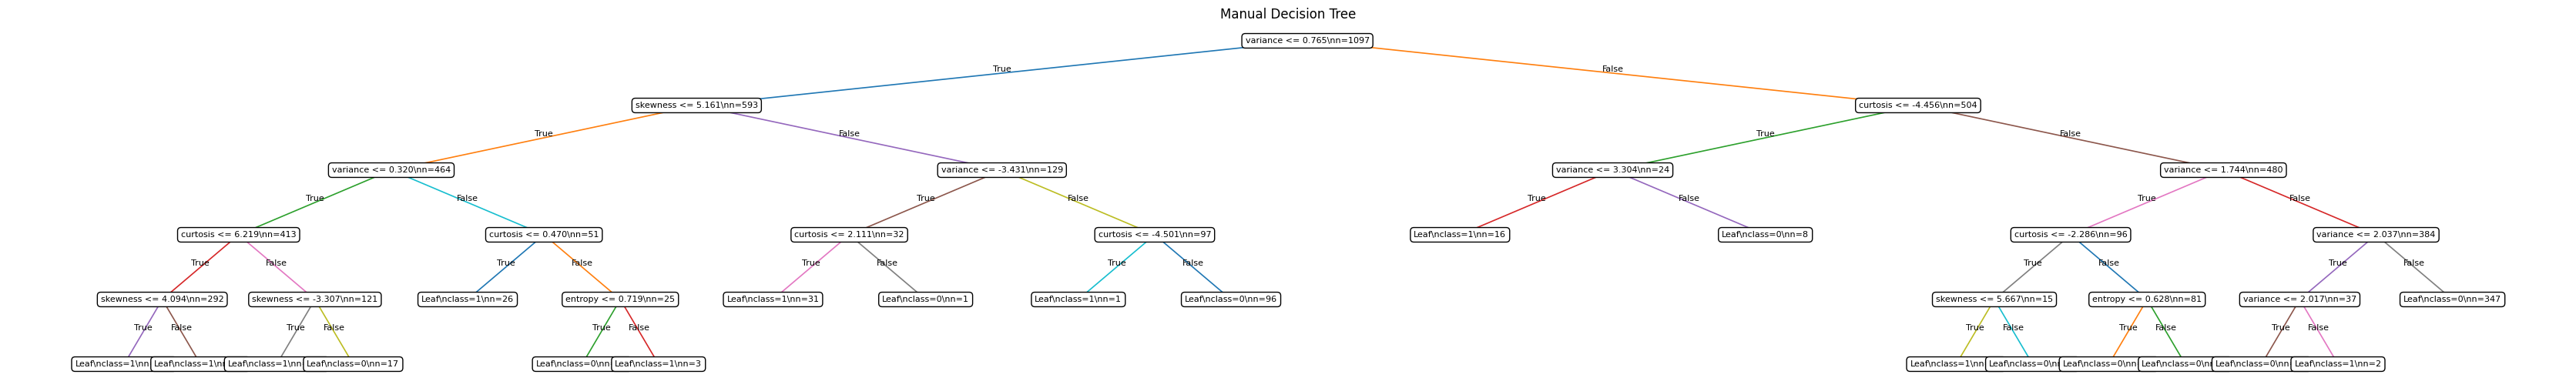

In [22]:
def plot_manual_tree(tree, feature_names):
    """Simple recursive tree diagram using Matplotlib."""
    nodes = []
    edges = []

    def collect(node, depth=0, parent_id=None, branch_label=""):
        node_id = len(nodes)
        if node["leaf"]:
            label = f"Leaf\\nclass={node['prediction']}\\nn={node['samples']}"
        else:
            label = (f"{feature_names[node['feature']]} <= "
                     f"{node['threshold']:.3f}\\nn={node['samples']}")
        nodes.append({"id": node_id, "depth": depth, "label": label})
        if parent_id is not None:
            edges.append((parent_id, node_id, branch_label))

        if not node["leaf"]:
            collect(node["left"], depth + 1, node_id, "True")
            collect(node["right"], depth + 1, node_id, "False")
        return node_id

    collect(tree)

    # Assign horizontal positions recursively.
    positions = {}
    leaf_counter = [0]

    def assign(node, x_left, x_right, depth, node_id):
        x = (x_left + x_right) / 2
        positions[node_id] = (x, -depth)
        if not node["leaf"]:
            left_id = next(e[1] for e in edges if e[0] == node_id and e[2] == "True")
            right_id = next(e[1] for e in edges if e[0] == node_id and e[2] == "False")
            assign(node["left"], x_left, x, depth + 1, left_id)
            assign(node["right"], x, x_right, depth + 1, right_id)

    assign(tree, 0, 1, 0, 0)

    fig, ax = plt.subplots(figsize=(max(10, len(nodes) * 1.1), 6))
    for parent_id, child_id, branch in edges:
        x1, y1 = positions[parent_id]
        x2, y2 = positions[child_id]
        ax.plot([x1, x2], [y1, y2], linewidth=1.2)
        ax.text((x1+x2)/2, (y1+y2)/2, branch, fontsize=8,
                ha="center", va="bottom")

    for node in nodes:
        x, y_pos = positions[node["id"]]
        ax.text(x, y_pos, node["label"], ha="center", va="center",
                fontsize=8,
                bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                          edgecolor="black"))

    ax.set_title("Manual Decision Tree")
    ax.axis("off")
    plt.show()


plot_manual_tree(manual_tree.tree_, feature_names)

## A7. Plot a 2D decision boundary

A two-dimensional plot can show only two input features. We use **variance** and **skewness** here. This is a separate two-feature model; it is not the four-feature final model.

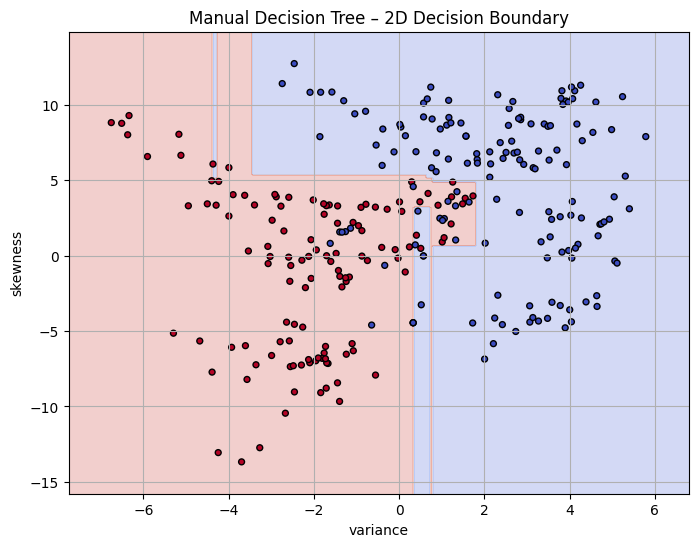

In [23]:
def plot_decision_boundary(model, X, y, feature_labels, title, padding=0.08):
    X = np.asarray(X)
    x0_min, x0_max = X[:, 0].min(), X[:, 0].max()
    x1_min, x1_max = X[:, 1].min(), X[:, 1].max()

    x0_pad = (x0_max - x0_min) * padding
    x1_pad = (x1_max - x1_min) * padding

    xx, yy = np.meshgrid(
        np.linspace(x0_min - x0_pad, x0_max + x0_pad, 300),
        np.linspace(x1_min - x1_pad, x1_max + x1_pad, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",
                edgecolors="black", s=18)
    plt.xlabel(feature_labels[0])
    plt.ylabel(feature_labels[1])
    plt.title(title)
    plt.show()


X_train_2d = X_train[:, :2]
X_test_2d = X_test[:, :2]

manual_tree_2d = DecisionTreeScratch(
    criterion="gini", max_depth=5
).fit(X_train_2d, y_train)

plot_decision_boundary(
    manual_tree_2d, X_test_2d, y_test,
    ["variance", "skewness"],
    "Manual Decision Tree – 2D Decision Boundary"
)

## A8. Compare with Scikit-learn DecisionTreeClassifier

Scikit-learn Decision Tree accuracy: 0.9927272727272727
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       153
           1       0.98      1.00      0.99       122

    accuracy                           0.99       275
   macro avg       0.99      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



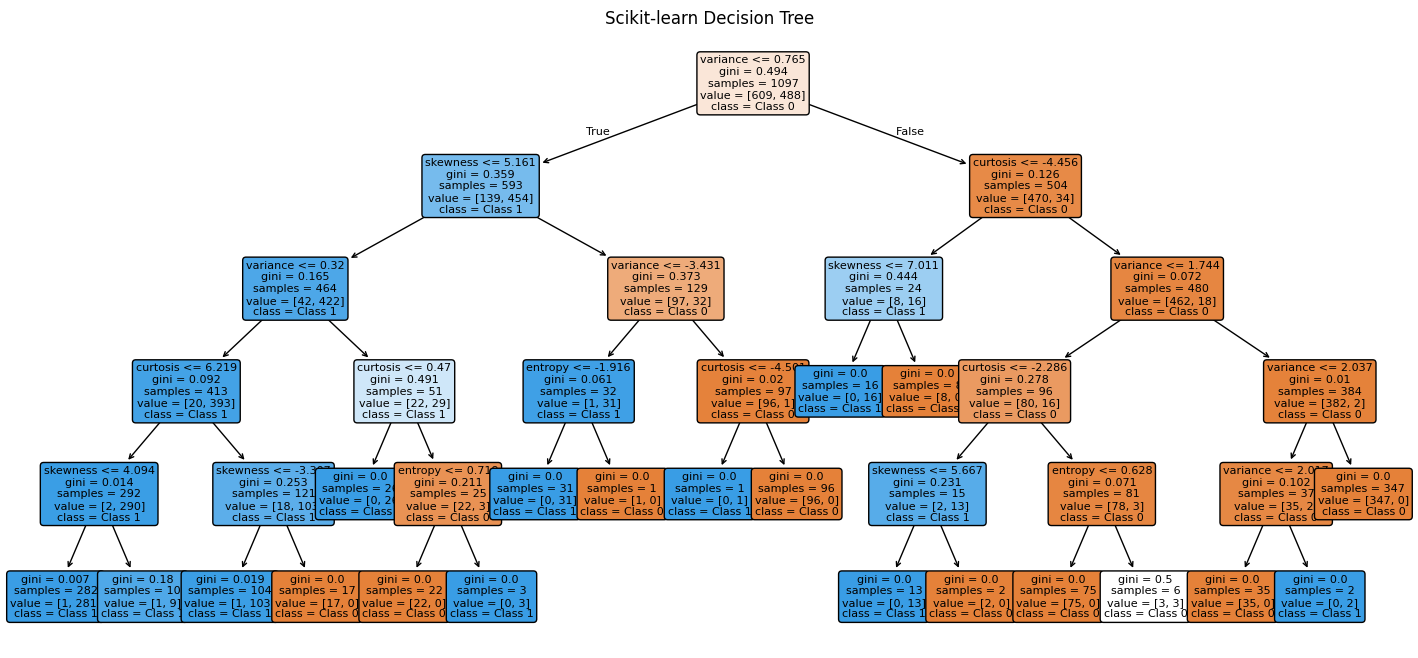

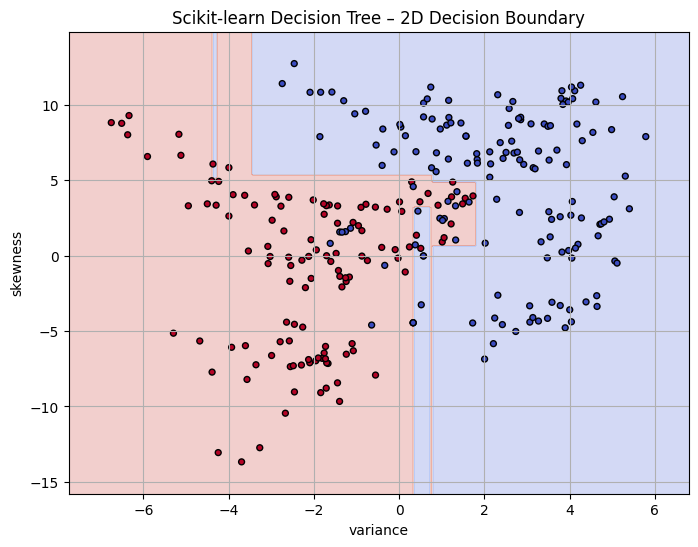

In [24]:
sk_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=RANDOM_STATE
)
sk_tree.fit(X_train, y_train)
y_pred_sk_tree = sk_tree.predict(X_test)

print("Scikit-learn Decision Tree accuracy:",
      accuracy_score(y_test, y_pred_sk_tree))
print(classification_report(y_test, y_pred_sk_tree, zero_division=0))

plt.figure(figsize=(18, 8))
plot_tree(
    sk_tree,
    feature_names=feature_names,
    class_names=["Class 0", "Class 1"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Scikit-learn Decision Tree")
plt.show()

sk_tree_2d = DecisionTreeClassifier(
    criterion="gini", max_depth=5, random_state=RANDOM_STATE
).fit(X_train_2d, y_train)

plot_decision_boundary(
    sk_tree_2d, X_test_2d, y_test,
    ["variance", "skewness"],
    "Scikit-learn Decision Tree – 2D Decision Boundary"
)

## A9. Compare Gini and Entropy; study maximum depth

gini     test accuracy: 0.9927
entropy  test accuracy: 0.9855


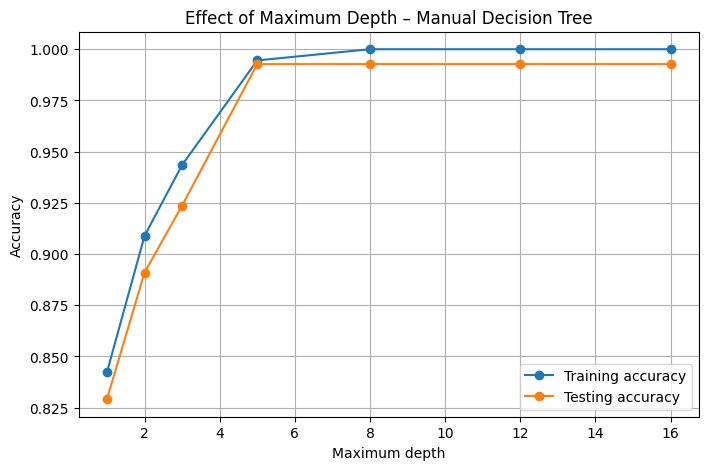

In [25]:
for criterion in ["gini", "entropy"]:
    model = DecisionTreeScratch(
        criterion=criterion, max_depth=5
    ).fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"{criterion:8s} test accuracy: {accuracy_score(y_test, pred):.4f}")

depth_values = [1, 2, 3, 5, 8, 12, 16]
train_scores, test_scores = [], []

for depth in depth_values:
    model = DecisionTreeScratch(
        criterion="gini", max_depth=depth
    ).fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(depth_values, train_scores, marker="o", label="Training accuracy")
plt.plot(depth_values, test_scores, marker="o", label="Testing accuracy")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Effect of Maximum Depth – Manual Decision Tree")
plt.legend()
plt.show()

# Part B – Linear Soft-Margin SVM from Scratch

A linear SVM finds a separating hyperplane:

\[
w^T x + b = 0
\]

The margin boundaries are:

\[
w^T x+b=+1,\qquad w^T x+b=-1
\]

The distance between the two margin boundaries is \(2/\|w\|\).

### Hinge loss

First map labels from \(\{0,1\}\) to \(\{-1,+1\}\). For one observation:

\[
L_i = \max(0, 1-y_i(w^T x_i+b))
\]

The objective implemented below is:

\[
J(w,b)=\frac{1}{2}\|w\|^2+
C\frac{1}{N}\sum_i \max(0,1-y_i(w^Tx_i+b))
\]

The gradient of the hinge-loss term is a subgradient. Only observations with margin \(y_i(w^Tx_i+b)<1\) contribute to the hinge-loss gradient.

## B1. Standardize features and convert labels

SVM optimization is sensitive to feature scale. Fit the scaler on the training set only, then use that same scaler to transform the test set. Labels are converted from 0/1 to -1/+1 for the manual SVM.

In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Scaled training feature means:", X_train_scaled.mean(axis=0))
print("SVM labels:", np.unique(y_train_svm))

Scaled training feature means: [-8.72390380e-17 -3.24666861e-16 -5.25458336e-16  5.76465848e-16]
SVM labels: [-1  1]


## B2. Implement the manual linear SVM

In [27]:
class LinearSVMScratch:
    def __init__(self, C=1.0, learning_rate=0.01, n_iters=3000):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        n_samples, n_features = X.shape
        self.w = np.zeros(n_features, dtype=float)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.n_iters):
            margins = y * (X @ self.w + self.b)
            violating = margins < 1

            # Gradient of 0.5 * ||w||^2 plus mean hinge loss.
            grad_w = self.w.copy()
            grad_b = 0.0

            if np.any(violating):
                grad_w -= self.C * np.mean(
                    (y[violating, None] * X[violating]), axis=0
                ) * (np.sum(violating) / n_samples)
                grad_b -= self.C * np.sum(y[violating]) / n_samples

            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            # Record objective for monitoring.
            current_hinge = np.maximum(
                0, 1 - y * (X @ self.w + self.b)
            )
            objective = 0.5 * np.dot(self.w, self.w) + self.C * np.mean(current_hinge)
            self.loss_history.append(objective)

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

### Gradient intuition

For a sample that satisfies the margin, its hinge loss is zero and it contributes no hinge-loss gradient. For a sample with margin below 1, it contributes \(-y_i x_i\) to the weight gradient and \(-y_i\) to the bias gradient. The regularization term contributes \(w\) to the weight gradient.

The implementation uses the average hinge loss, so the hinge-loss gradients are divided by the total number of training observations.

## B3. Train the manual SVM and inspect the loss

Manual Linear SVM accuracy: 0.8836363636363637


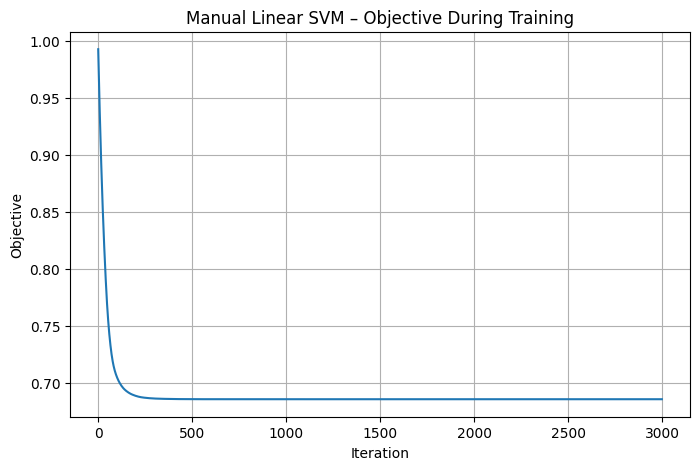

In [28]:
manual_svm = LinearSVMScratch(
    C=1.0,
    learning_rate=0.01,
    n_iters=3000
)
manual_svm.fit(X_train_scaled, y_train_svm)

manual_svm_pred = manual_svm.predict(X_test_scaled)
manual_svm_pred_01 = np.where(manual_svm_pred == -1, 0, 1)

print("Manual Linear SVM accuracy:",
      accuracy_score(y_test, manual_svm_pred_01))

plt.figure(figsize=(8, 5))
plt.plot(manual_svm.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Objective")
plt.title("Manual Linear SVM – Objective During Training")
plt.show()

## B4. Plot decision boundary, margins, and margin-violating samples

For a 2D model, the decision boundary is \(w_1x_1+w_2x_2+b=0\), and the margins are the parallel lines with right-hand sides +1 and -1. The plot below uses a separate SVM trained on the two selected features. Samples with \(y_i f(x_i)<1\) violate the margin.

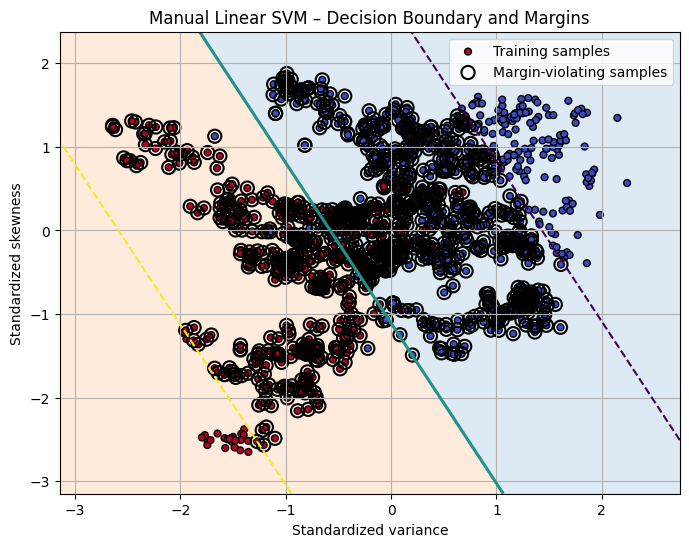

In [29]:
# Fit a separate 2-feature scaler and model for the 2D plot.
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

svm_2d = LinearSVMScratch(
    C=1.0, learning_rate=0.01, n_iters=3000
).fit(X_train_2d_scaled, y_train_svm)

def plot_linear_svm_margins(model, X_scaled, y_pm, title):
    x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
    y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, scores, levels=[-100, 0, 100],
                 alpha=0.15, colors=["tab:blue", "tab:orange"])
    plt.contour(xx, yy, scores, levels=[-1, 0, 1],
                linestyles=["--", "-", "--"],
                linewidths=[1.5, 2.2, 1.5])

    margins = y_pm * model.decision_function(X_scaled)
    violating = margins < 1

    plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_pm,
                cmap="coolwarm", edgecolors="black", s=24,
                label="Training samples")
    if np.any(violating):
        plt.scatter(X_scaled[violating, 0], X_scaled[violating, 1],
                    facecolors="none", edgecolors="black", s=90,
                    linewidths=1.5, label="Margin-violating samples")

    plt.xlabel("Standardized variance")
    plt.ylabel("Standardized skewness")
    plt.title(title)
    plt.legend()
    plt.show()

plot_linear_svm_margins(
    svm_2d, X_train_2d_scaled, y_train_svm,
    "Manual Linear SVM – Decision Boundary and Margins"
)

## B5. Compare with Scikit-learn Linear SVM

`LinearSVC` is used as the library comparison. Its optimization implementation and objective conventions are not identical to the manual implementation, so small differences in fitted boundaries or scores are expected. Both models use standardized data.

In [30]:
sk_linear_svm = LinearSVC(
    C=1.0,
    max_iter=10000,
    random_state=RANDOM_STATE
)
sk_linear_svm.fit(X_train_scaled, y_train_svm)

sk_svm_pred_pm = sk_linear_svm.predict(X_test_scaled)
sk_svm_pred_01 = np.where(sk_svm_pred_pm == -1, 0, 1)

print("Manual Linear SVM accuracy:",
      accuracy_score(y_test, manual_svm_pred_01))
print("Scikit-learn LinearSVC accuracy:",
      accuracy_score(y_test, sk_svm_pred_01))

Manual Linear SVM accuracy: 0.8836363636363637
Scikit-learn LinearSVC accuracy: 0.9854545454545455


## B6. Study regularization C, learning rate, and iterations

In [31]:
# Effect of C (each model is trained with the same standardized data).
C_values = [0.01, 0.1, 1.0, 10.0]
for c_value in C_values:
    model = LinearSVMScratch(
        C=c_value, learning_rate=0.01, n_iters=3000
    ).fit(X_train_scaled, y_train_svm)
    pred = np.where(model.predict(X_test_scaled) == -1, 0, 1)
    print(f"C={c_value:>5}: test accuracy={accuracy_score(y_test, pred):.4f}")

# Effect of learning rate and number of iterations.
settings = [
    (0.001, 3000),
    (0.01, 3000),
    (0.05, 3000),
    (0.01, 500),
    (0.01, 6000)
]
for lr, iters in settings:
    model = LinearSVMScratch(
        C=1.0, learning_rate=lr, n_iters=iters
    ).fit(X_train_scaled, y_train_svm)
    pred = np.where(model.predict(X_test_scaled) == -1, 0, 1)
    print(f"learning_rate={lr}, iterations={iters}, "
          f"accuracy={accuracy_score(y_test, pred):.4f}, "
          f"final objective={model.loss_history[-1]:.4f}")

C= 0.01: test accuracy=0.5564
C=  0.1: test accuracy=0.5564
C=  1.0: test accuracy=0.8836
C= 10.0: test accuracy=0.9709
learning_rate=0.001, iterations=3000, accuracy=0.8800, final objective=0.6862
learning_rate=0.01, iterations=3000, accuracy=0.8836, final objective=0.6856
learning_rate=0.05, iterations=3000, accuracy=0.8836, final objective=0.6856
learning_rate=0.01, iterations=500, accuracy=0.8800, final objective=0.6856
learning_rate=0.01, iterations=6000, accuracy=0.8836, final objective=0.6856


# Part C – Kernel SVM and Nonlinear Boundaries

A linear SVM can fail when classes cannot be separated by a straight line. A kernel computes similarity in a way that allows SVM to form nonlinear decision boundaries.

The assignment asks for linear, polynomial, and RBF kernels. We use the `make_moons` synthetic dataset.

## C1. Generate a nonlinear dataset

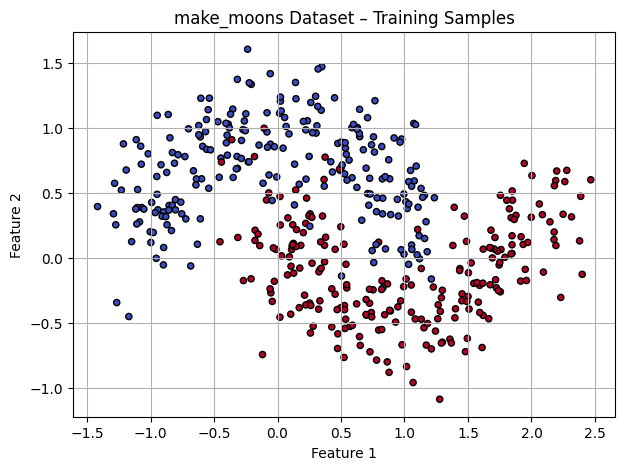

In [32]:
X_moons, y_moons = make_moons(
    n_samples=600,
    noise=0.22,
    random_state=RANDOM_STATE
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_moons
)

plt.figure(figsize=(7, 5))
plt.scatter(X_moons_train[:, 0], X_moons_train[:, 1],
            c=y_moons_train, cmap="coolwarm", edgecolors="black", s=20)
plt.title("make_moons Dataset – Training Samples")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## C2. Train SVMs with three kernels

In [33]:
kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial": SVC(kernel="poly", degree=3, C=1.0, gamma="scale", coef0=1),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

kernel_results = {}

for name, model in kernel_models.items():
    model.fit(X_moons_train, y_moons_train)
    pred = model.predict(X_moons_test)
    kernel_results[name] = {
        "model": model,
        "accuracy": accuracy_score(y_moons_test, pred)
    }
    print(f"{name:12s} accuracy: {kernel_results[name]['accuracy']:.4f}")

Linear       accuracy: 0.8667
Polynomial   accuracy: 0.9467
RBF          accuracy: 0.9400


## C3. Plot and compare the three decision boundaries

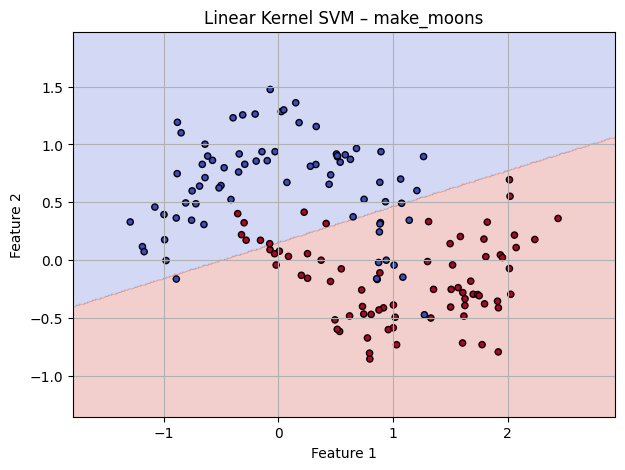

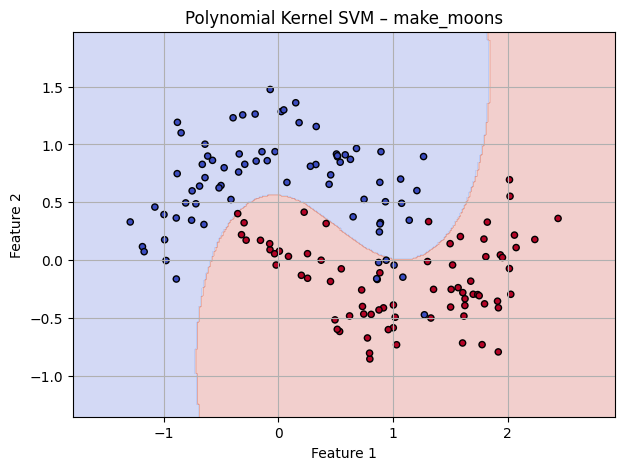

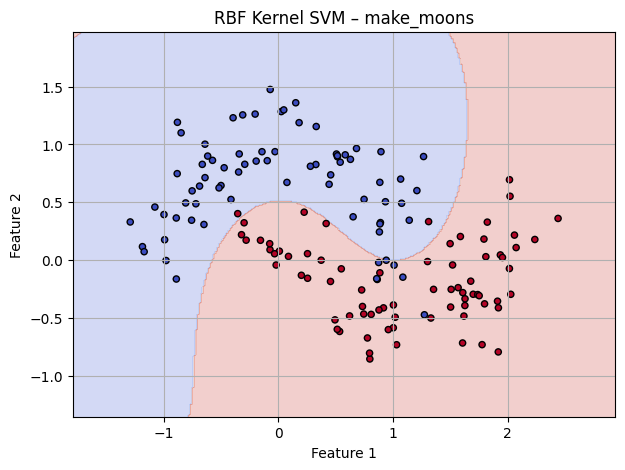

In [34]:
def plot_sklearn_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",
                edgecolors="black", s=20)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.show()


for name, result in kernel_results.items():
    plot_sklearn_boundary(
        result["model"], X_moons_test, y_moons_test,
        f"{name} Kernel SVM – make_moons"
    )

### C4. Observations to discuss

- **Linear kernel:** produces a straight decision boundary. It may underfit interlocking moon-shaped classes.
- **Polynomial kernel:** can represent curved boundaries through polynomial feature interactions. Its shape depends on degree and other parameters.
- **RBF kernel:** can form flexible nonlinear boundaries based on local similarities. It can model complex shapes, but an overly flexible setting may overfit.

The best kernel should be judged from the plotted boundary and held-out test performance, not assumed in advance.

# Part D – Final Comparison on the Banknote Dataset

Train and compare five models using **all four features**:

1. Manual Decision Tree
2. Scikit-learn Decision Tree
3. Manual Linear SVM
4. Scikit-learn Linear SVM
5. Scikit-learn RBF SVM

All models use the same train-test split. SVMs use standardized features; Decision Trees use the original feature values.

## D1. Fit the five final models and measure time

In [35]:
final_models = {}
timing_rows = []

# 1. Manual Decision Tree
start = time.perf_counter()
final_manual_tree = DecisionTreeScratch(
    criterion="gini", max_depth=5
).fit(X_train, y_train)
tree_train_time = time.perf_counter() - start

start = time.perf_counter()
pred = final_manual_tree.predict(X_test)
tree_predict_time = time.perf_counter() - start
final_models["Manual Decision Tree"] = (final_manual_tree, pred)
timing_rows.append(("Manual Decision Tree", tree_train_time, tree_predict_time))

# 2. Scikit-learn Decision Tree
start = time.perf_counter()
final_sk_tree = DecisionTreeClassifier(
    criterion="gini", max_depth=5, random_state=RANDOM_STATE
).fit(X_train, y_train)
sk_tree_train_time = time.perf_counter() - start

start = time.perf_counter()
pred = final_sk_tree.predict(X_test)
sk_tree_predict_time = time.perf_counter() - start
final_models["Scikit-learn Decision Tree"] = (final_sk_tree, pred)
timing_rows.append(("Scikit-learn Decision Tree", sk_tree_train_time, sk_tree_predict_time))

# 3. Manual Linear SVM
start = time.perf_counter()
final_manual_svm = LinearSVMScratch(
    C=1.0, learning_rate=0.01, n_iters=3000
).fit(X_train_scaled, y_train_svm)
manual_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
pred_pm = final_manual_svm.predict(X_test_scaled)
pred = np.where(pred_pm == -1, 0, 1)
manual_svm_predict_time = time.perf_counter() - start
final_models["Manual Linear SVM"] = (final_manual_svm, pred)
timing_rows.append(("Manual Linear SVM", manual_svm_train_time, manual_svm_predict_time))

# 4. Scikit-learn Linear SVM
start = time.perf_counter()
final_sk_linear_svm = LinearSVC(
    C=1.0, max_iter=10000, random_state=RANDOM_STATE
).fit(X_train_scaled, y_train_svm)
sk_linear_train_time = time.perf_counter() - start

start = time.perf_counter()
pred_pm = final_sk_linear_svm.predict(X_test_scaled)
pred = np.where(pred_pm == -1, 0, 1)
sk_linear_predict_time = time.perf_counter() - start
final_models["Scikit-learn Linear SVM"] = (final_sk_linear_svm, pred)
timing_rows.append(("Scikit-learn Linear SVM", sk_linear_train_time, sk_linear_predict_time))

# 5. Scikit-learn RBF SVM
start = time.perf_counter()
final_rbf_svm = SVC(kernel="rbf", C=1.0, gamma="scale")
final_rbf_svm.fit(X_train_scaled, y_train)
rbf_train_time = time.perf_counter() - start

start = time.perf_counter()
pred = final_rbf_svm.predict(X_test_scaled)
rbf_predict_time = time.perf_counter() - start
final_models["Scikit-learn RBF SVM"] = (final_rbf_svm, pred)
timing_rows.append(("Scikit-learn RBF SVM", rbf_train_time, rbf_predict_time))

print("All five models trained.")

All five models trained.


## D2. Calculate accuracy, precision, recall, and F1-score

In [36]:
metric_rows = []

for model_name, (_, predictions) in final_models.items():
    metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

metrics_df = pd.DataFrame(metric_rows).set_index("Model")
display(metrics_df.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Manual Decision Tree,0.9927,0.9839,1.0000,0.9919
Scikit-learn Decision Tree,0.9927,0.9839,1.0000,0.9919
Manual Linear SVM,0.8836,0.9412,0.7869,0.8571
Scikit-learn Linear SVM,0.9855,0.9683,1.0000,0.9839
Scikit-learn RBF SVM,1.0000,1.0000,1.0000,1.0000


## D3. Compare training and prediction times

In [37]:
timing_df = pd.DataFrame(
    timing_rows,
    columns=["Model", "Training time (seconds)", "Prediction time (seconds)"]
).set_index("Model")

display(timing_df)

,Training time (seconds),Prediction time (seconds)
Model,,
Manual Decision Tree,2.376229,0.000471
Scikit-learn Decision Tree,0.003619,0.000254
Manual Linear SVM,0.730590,0.000226
Scikit-learn Linear SVM,0.002792,0.000497
Scikit-learn RBF SVM,0.009199,0.003832


## D4. Confusion matrices

In [38]:
for model_name, (_, predictions) in final_models.items():
    cm = confusion_matrix(y_test, predictions)
    print(model_name)
    print(cm)
    print()

Manual Decision Tree
[[151   2]
 [  0 122]]

Scikit-learn Decision Tree
[[151   2]
 [  0 122]]

Manual Linear SVM
[[147   6]
 [ 26  96]]

Scikit-learn Linear SVM
[[149   4]
 [  0 122]]

Scikit-learn RBF SVM
[[153   0]
 [  0 122]]



## D5. 2D decision-boundary comparison

For this visualization only, each model is refitted using the two selected features. This is separate from the final four-feature evaluation above. The SVM visualization models use their own scaler fitted on the two-feature training data.

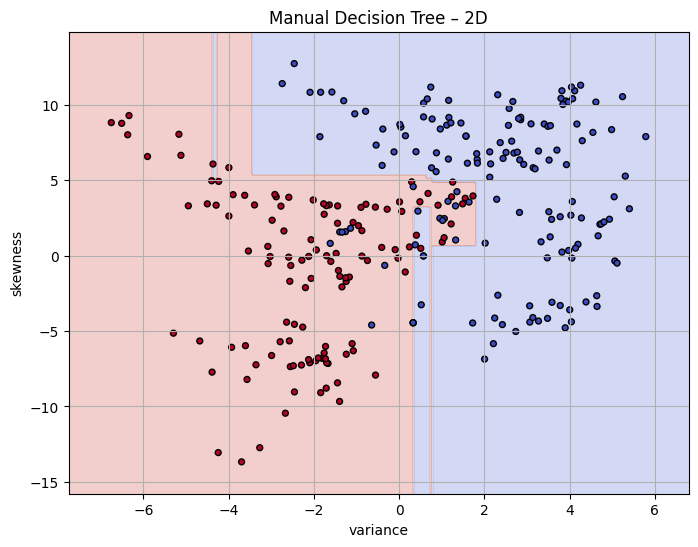

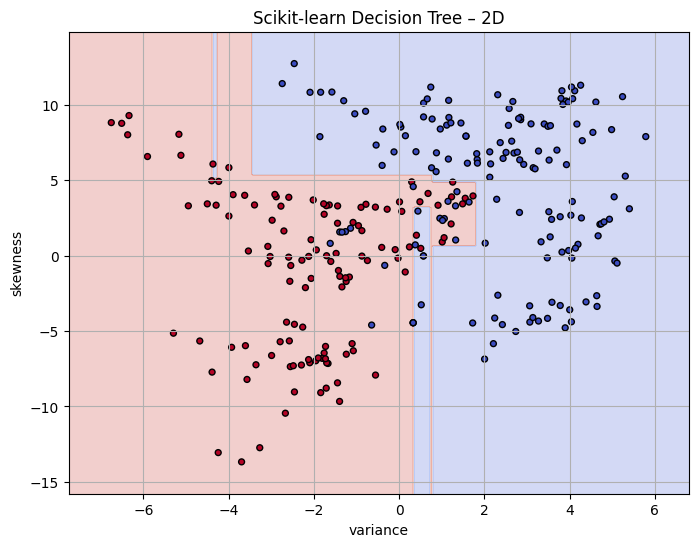

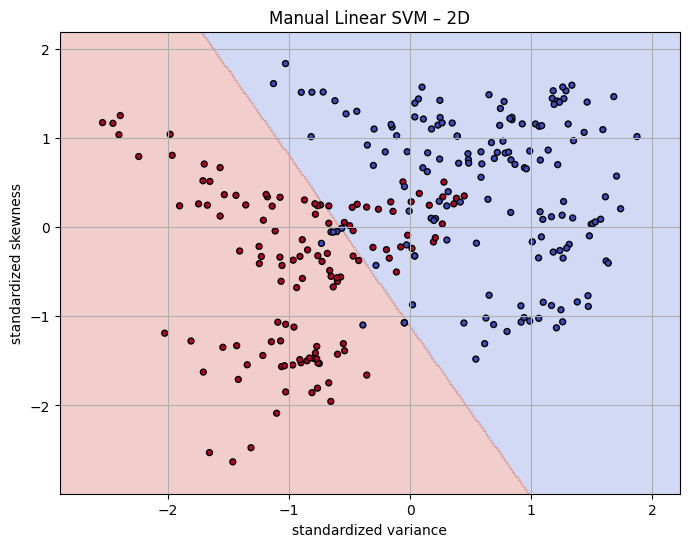

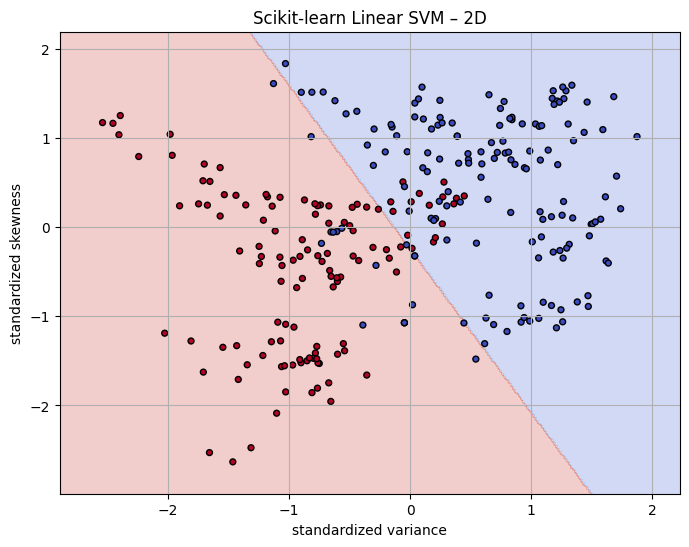

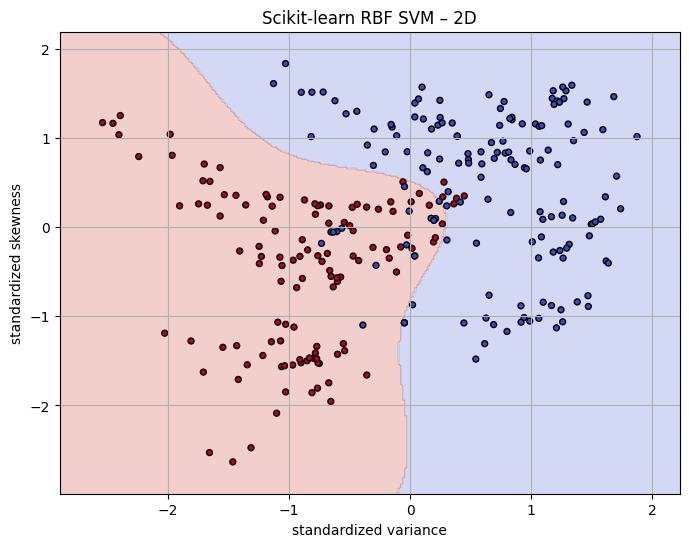

In [39]:
# Trees on two raw features.
tree_2d_manual_final = DecisionTreeScratch(
    criterion="gini", max_depth=5
).fit(X_train_2d, y_train)

tree_2d_sklearn_final = DecisionTreeClassifier(
    criterion="gini", max_depth=5, random_state=RANDOM_STATE
).fit(X_train_2d, y_train)

# SVMs on two standardized features.
scaler_2d_final = StandardScaler()
X_train_2d_scaled_final = scaler_2d_final.fit_transform(X_train_2d)
X_test_2d_scaled_final = scaler_2d_final.transform(X_test_2d)

manual_svm_2d_final = LinearSVMScratch(
    C=1.0, learning_rate=0.01, n_iters=3000
).fit(X_train_2d_scaled_final, y_train_svm)

sk_linear_svm_2d_final = LinearSVC(
    C=1.0, max_iter=10000, random_state=RANDOM_STATE
).fit(X_train_2d_scaled_final, y_train_svm)

rbf_svm_2d_final = SVC(
    kernel="rbf", C=1.0, gamma="scale"
).fit(X_train_2d_scaled_final, y_train)

# Plot tree boundaries in raw feature coordinates.
plot_decision_boundary(
    tree_2d_manual_final, X_test_2d, y_test,
    ["variance", "skewness"], "Manual Decision Tree – 2D"
)
plot_decision_boundary(
    tree_2d_sklearn_final, X_test_2d, y_test,
    ["variance", "skewness"], "Scikit-learn Decision Tree – 2D"
)

# Plot SVM boundaries in standardized coordinates.
plot_decision_boundary(
    manual_svm_2d_final, X_test_2d_scaled_final, y_test_svm,
    ["standardized variance", "standardized skewness"],
    "Manual Linear SVM – 2D"
)

class SklearnSVM2DWrapper:
    def __init__(self, model):
        self.model = model
    def predict(self, X):
        return self.model.predict(X)

plot_decision_boundary(
    SklearnSVM2DWrapper(sk_linear_svm_2d_final),
    X_test_2d_scaled_final, y_test_svm,
    ["standardized variance", "standardized skewness"],
    "Scikit-learn Linear SVM – 2D"
)
plot_decision_boundary(
    rbf_svm_2d_final,
    X_test_2d_scaled_final, y_test,
    ["standardized variance", "standardized skewness"],
    "Scikit-learn RBF SVM – 2D"
)

## D6. Discussion and observations for the README

Use the actual values printed by your notebook. Do not copy assumed scores.

Discuss these points:

1. **Interpretability:** A Decision Tree can be explained through feature-threshold rules. SVMs are generally less directly interpretable.
2. **Scaling:** Decision Trees generally do not require feature scaling. SVMs are sensitive to feature scales, so standardization is important.
3. **Overfitting:** A very deep Decision Tree can fit noise. SVM overfitting depends on regularization, kernel choice, and hyperparameters.
4. **Model complexity:** Tree depth and number of nodes affect tree complexity. For SVMs, the kernel and support vectors affect model behaviour and prediction cost.
5. **Performance:** Compare all four metrics in the results table. Accuracy alone may hide differences in precision and recall.
6. **Time:** Compare training and prediction times, noting that timings depend on the machine and software environment.

### Manual versus library implementations

The manual Decision Tree and manual SVM are educational implementations. Small differences from Scikit-learn are expected because implementation details, optimization procedures, stopping rules, and parameter conventions can differ.